# Reto 3 — Modelo de clustering (K-Means)

Objetivo: segmentar a los clientes con K-Means sobre la matriz preparada en el Reto 2 (`data/processed/X_model.csv`: una fila por cliente, sin nulos, numéricas escaladas).

Pasos, en el orden del enunciado:

1. Ejecución de K-Means para un rango de valores de k.
2. Método del codo para seleccionar el k óptimo.
3. Silhouette Score para cada valor de k.
4. Entrenamiento del modelo final con el k elegido.
5. Distribución de clientes por cluster.

> Requisito: ejecutar antes `02_feature_engineering.ipynb`, que genera `data/processed/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.4f}".format)

PROCESSED = next(p for p in (Path("data/processed"), Path("../data/processed")) if p.exists())

X = pd.read_csv(PROCESSED / "X_model.csv", index_col="client_id")
print(f"Matriz: {X.shape[0]:,} clientes × {X.shape[1]} features | nulos: {X.isna().sum().sum()}")

Matriz: 173,454 clientes × 19 features | nulos: 0


## 1. K-Means para un rango de k

Se prueba **k = 2…12**: por debajo de 2 no hay segmentación y por encima de 12 los segmentos dejan de ser manejables para una campaña de marketing.

Configuración (idéntica para todos los k):

| Parámetro | Valor | Motivo |
|---|---|---|
| `init` | `k-means++` | Centroides iniciales separados entre sí: converge antes y evita malos mínimos locales |
| `n_init` | 10 | Se ejecuta 10 veces con distintas inicializaciones y se queda la de menor inercia |
| `max_iter` | 300 | Tope de seguridad de iteraciones |
| `tol` | 1e-4 | Criterio de finalización (ver abajo) |
| `random_state` | 0, 1, 2, 3, 4 | **5 semillas por k** para comprobar que el resultado no depende de la inicialización |

**Varias semillas.** `n_init=10` ya prueba 10 inicializaciones, pero todas derivan de una misma semilla. Para comprobar que la inercia y el Silhouette de cada k no son fruto de una inicialización concreta, cada k se entrena con **5 semillas distintas** y se reporta la media y la desviación entre ellas.

**Criterio de finalización.** Los apuntes (T2-2) dan tres criterios: (1) no hay reasignaciones de instancias a otros clusters, (2) los centroides no cambian o el cambio es mínimo, (3) la función de coste J apenas disminuye. sklearn aplica (1) — si las asignaciones no cambian entre dos iteraciones, para — y (2) mediante `tol`: para cuando el desplazamiento de los centroides es menor que `tol` (relativo a la varianza de los datos). El criterio (3) queda cubierto de forma implícita: si los centroides no se mueven, J tampoco baja. `max_iter` solo actúa si no converge; se comprueba con `n_iter_` que ningún modelo llega al tope.

**Silhouette con muestreo.** El Silhouette Score necesita las distancias entre todos los pares de puntos (O(n²)): con 173.454 clientes son ~3·10¹⁰ distancias y no es viable. Se calcula sobre **5 muestras aleatorias de 20.000 clientes** (las mismas para todos los k y semillas) y se toma la media.

> La celda siguiente entrena 55 modelos (11 valores de k × 5 semillas) y tarda unos 9 minutos.

In [2]:
K_RANGE = range(2, 13)
SEEDS = [0, 1, 2, 3, 4]
KMEANS_PARAMS = dict(init="k-means++", n_init=10, max_iter=300, tol=1e-4)

rng = np.random.default_rng(42)
samples = [rng.choice(len(X), 20_000, replace=False) for _ in range(5)]
X_np = X.to_numpy()

runs = []
for k in K_RANGE:
    for seed in SEEDS:
        model = KMeans(n_clusters=k, random_state=seed, **KMEANS_PARAMS).fit(X_np)
        sizes = np.bincount(model.labels_) / len(X_np)
        runs.append({
            "k": k,
            "seed": seed,
            "inercia": model.inertia_,
            "silhouette": np.mean([silhouette_score(X_np[idx], model.labels_[idx]) for idx in samples]),
            "iteraciones": model.n_iter_,
            "cluster_min_%": sizes.min() * 100,
        })

runs = pd.DataFrame(runs)
assert (runs["iteraciones"] < KMEANS_PARAMS["max_iter"]).all(), "Algún modelo no ha convergido"

results = runs.groupby("k").agg(
    inercia=("inercia", "mean"),
    inercia_std=("inercia", "std"),
    silhouette=("silhouette", "mean"),
    silhouette_std=("silhouette", "std"),
    iteraciones_max=("iteraciones", "max"),
    cluster_min_pct=("cluster_min_%", "mean"),
)
results["caida_inercia_%"] = -results["inercia"].pct_change() * 100
results

,inercia,inercia_std,silhouette,silhouette_std,iteraciones_max,cluster_min_pct,caida_inercia_%
k,,,,,,,
2,"1,569,498.8822",1.8323,0.1118,0.0000,22,47.3026,NaN
3,"1,426,225.9927",0.5882,0.1200,0.0000,66,19.2933,9.1286
4,"1,317,127.8896",0.2864,0.1306,0.0000,35,10.3503,7.6494
5,"1,218,538.5530",0.6344,0.1355,0.0000,52,10.1243,7.4852
6,"1,152,461.2028",1.8290,0.1219,0.0000,58,10.0585,5.4227
7,"1,099,150.9687",1.9144,0.1207,0.0000,59,8.6394,4.6258
8,"1,059,568.4257",1.7995,0.1135,0.0000,28,8.1014,3.6012
9,"1,029,512.0810",141.6160,0.1146,0.0032,45,7.3647,2.8367
10,"999,953.4512",2.1330,0.1124,0.0001,46,7.2529,2.8711


**Interpretación**

- Los 55 modelos convergen antes del tope de 300 iteraciones (`iteraciones_max`), por lo que paran por el criterio de finalización y no por el límite.
- **Hasta k = 8 el resultado no depende de la semilla**: la desviación de la inercia entre semillas es de unas pocas unidades sobre más de un millón y la del Silhouette es prácticamente 0. Las 5 semillas encuentran la misma solución.
- **A partir de k = 9 aparecen diferencias entre semillas** (desviaciones de la inercia de cientos de unidades en k = 9, 11 y 12): con tantos clusters, K-Means cae en mínimos locales distintos según la inicialización. Es un argumento más contra elegir un k alto.
- `cluster_min_pct` indica el tamaño medio del cluster más pequeño: a partir de k = 11 aparece un cluster de ~3 % de los clientes.

## 2. Método del codo

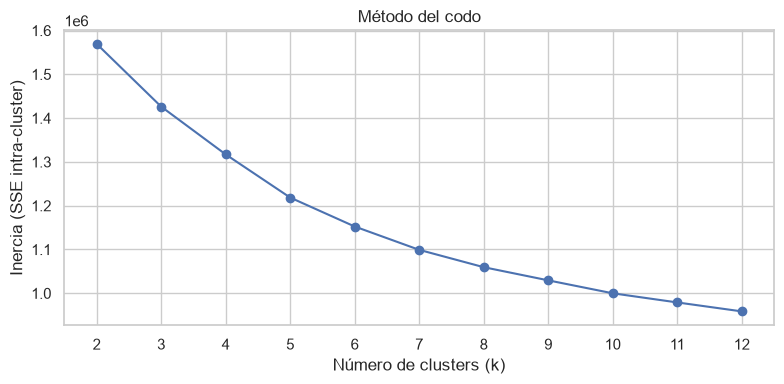

,inercia,caida_inercia_%
k,,
2,"1,569,498.8822",NaN
3,"1,426,225.9927",9.1286
4,"1,317,127.8896",7.6494
5,"1,218,538.5530",7.4852
6,"1,152,461.2028",5.4227
7,"1,099,150.9687",4.6258
8,"1,059,568.4257",3.6012
9,"1,029,512.0810",2.8367
10,"999,953.4512",2.8711


In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(results.index, results["inercia"], yerr=results["inercia_std"], marker="o", capsize=3)
ax.set(title="Método del codo", xlabel="Número de clusters (k)", ylabel="Inercia (SSE intra-cluster)", xticks=list(K_RANGE))
plt.tight_layout()
plt.show()

results[["inercia", "caida_inercia_%"]]

**Interpretación**

- La inercia siempre baja al aumentar k (con k = n sería 0), así que no se busca el mínimo sino el **codo**: el punto a partir del cual añadir clusters aporta poco.
- Las caídas son grandes hasta **k = 5** (cada cluster nuevo reduce la inercia entre un 7,5 % y un 9 %); en k = 6 bajan al 5,4 % y a partir de k = 7 quedan por debajo del 5 %.
- El codo no es brusco (algo habitual con datos reales de clientes), pero apunta a la zona **k = 5–6**.

## 3. Silhouette Score para cada k

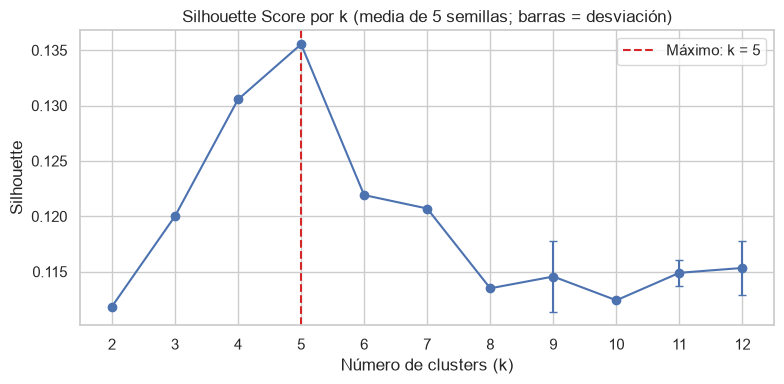

,silhouette,silhouette_std
k,,
2,0.1118,0.0000
3,0.1200,0.0000
4,0.1306,0.0000
5,0.1355,0.0000
6,0.1219,0.0000
7,0.1207,0.0000
8,0.1135,0.0000
9,0.1146,0.0032
10,0.1124,0.0001


In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(results.index, results["silhouette"], yerr=results["silhouette_std"], marker="o", capsize=3)
best_k = results["silhouette"].idxmax()
ax.axvline(best_k, color="tab:red", linestyle="--", label=f"Máximo: k = {best_k}")
ax.set(title="Silhouette Score por k (media de 5 semillas; barras = desviación)", xlabel="Número de clusters (k)", ylabel="Silhouette", xticks=list(K_RANGE))
ax.legend()
plt.tight_layout()
plt.show()

results[["silhouette", "silhouette_std"]]

**Interpretación**

- El Silhouette varía entre −1 y 1: mide si cada cliente está más cerca de su cluster (cohesión) que del cluster vecino (separación).
- El máximo está en **k = 5** con las 5 semillas; a partir de ahí baja y se estanca.
- Los valores son bajos en todos los k (~0,11–0,14; como referencia orientativa, por debajo de 0,25 no hay grupos claramente separados). Cada cliente está, de media, solo algo más cerca de su cluster que del vecino. Posibles motivos:
  1. **Los clientes forman un continuo**: antigüedad, edad del coche o poder adquisitivo varían de forma gradual, y K-Means parte ese continuo, dejando muchos clientes en la frontera entre segmentos.
  2. **19 dimensiones**: con muchas dimensiones las distancias entre puntos tienden a parecerse, lo que acerca la distancia al propio cluster y al vecino.
  3. **Mezcla de variables continuas y binarias / one-hot**, que encajan peor con la distancia euclídea.
- Por tanto, los 5 segmentos no son grupos naturales aislados, sino una **partición útil** de un continuo de clientes (reproducible entre semillas, ver sección 4). Para elegir k lo que importa es la comparación **entre** valores de k, y ahí k = 5 es el mejor.

## 4. Elección de k y modelo final

| Criterio | Resultado |
|---|---|
| Método del codo | Las caídas de inercia son grandes hasta k = 5 (≥ 7,5 %) y a partir de k = 6 se reducen (≤ 5,4 %) |
| Silhouette Score | Máximo en k = 5, con las 5 semillas |
| Robustez frente a la semilla | Con k = 5 las 5 semillas dan la misma inercia y Silhouette; las inestabilidades aparecen a partir de k = 9 |
| Tamaño de los clusters | Con k = 5 el cluster más pequeño tiene ~10 % de los clientes: ningún segmento residual |
| Utilidad para negocio | 5 segmentos es un número manejable para diseñar campañas diferenciadas (k = 2–3 sería demasiado genérico) |

**Se elige k = 5**: es el único valor en el que coinciden el codo y el máximo del Silhouette.

**Modelo final.** Se entrena k = 5 con las 5 semillas y se comprueba que todas asignan a los clientes igual mediante el **Adjusted Rand Index** (ARI: 1 = asignaciones idénticas, aunque los números de cluster estén permutados; 0 = coincidencia al azar). Como modelo final se queda el de **menor inercia**, que es el criterio de K-Means para elegir entre inicializaciones.

In [5]:
from itertools import combinations

from sklearn.metrics import adjusted_rand_score

K_FINAL = 5

models = {seed: KMeans(n_clusters=K_FINAL, random_state=seed, **KMEANS_PARAMS).fit(X_np) for seed in SEEDS}

ari = pd.Series({
    (a, b): adjusted_rand_score(models[a].labels_, models[b].labels_)
    for a, b in combinations(SEEDS, 2)
}, name="ARI")
print(f"ARI entre semillas (10 pares): mínimo {ari.min():.4f} | medio {ari.mean():.4f}")

best_seed = min(models, key=lambda s: models[s].inertia_)
kmeans = models[best_seed]
labels = pd.Series(kmeans.labels_, index=X.index, name="cluster")

print(f"Modelo final: semilla {best_seed}")
print(f"Iteraciones hasta converger: {kmeans.n_iter_} (tope: {KMEANS_PARAMS['max_iter']})")
print(f"Inercia: {kmeans.inertia_:,.0f}")
print(f"Silhouette (media de 5 muestras): {np.mean([silhouette_score(X_np[i], kmeans.labels_[i]) for i in samples]):.4f}")

ARI entre semillas (10 pares): mínimo 0.9930 | medio 0.9965
Modelo final: semilla 0
Iteraciones hasta converger: 10 (tope: 300)
Inercia: 1,218,538


Silhouette (media de 5 muestras): 0.1355


**Interpretación**

- El ARI entre las 5 semillas es superior a 0,99: los segmentos son prácticamente los mismos sea cual sea la inicialización, así que la segmentación es reproducible.
- Esta comprobación mide la robustez frente a la **inicialización**. La robustez frente a los **datos** (quitar parte de los clientes y reentrenar) es el reto avanzado de jackknife.

## 5. Distribución de clientes por cluster

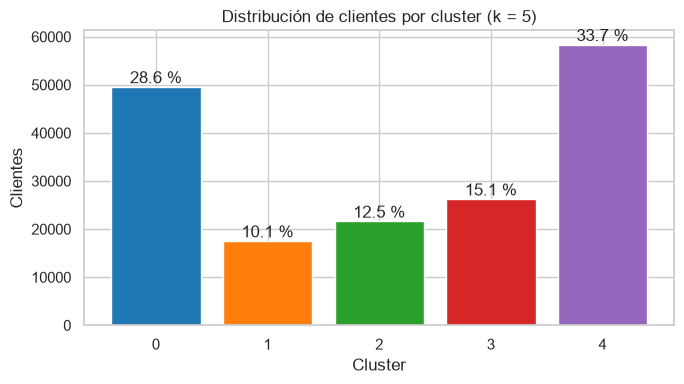

,clientes,%
cluster,,
0,"49,610",28.6
1,"17,561",10.1
2,"21,646",12.5
3,"26,257",15.1
4,"58,380",33.7


In [6]:
distribution = labels.value_counts().sort_index().to_frame("clientes")
distribution["%"] = distribution["clientes"] / distribution["clientes"].sum() * 100

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(distribution.index.astype(str), distribution["clientes"], color=sns.color_palette("tab10", K_FINAL))
ax.bar_label(bars, labels=[f"{p:.1f} %" for p in distribution["%"]])
ax.set(title=f"Distribución de clientes por cluster (k = {K_FINAL})", xlabel="Cluster", ylabel="Clientes")
plt.tight_layout()
plt.show()

distribution.style.format({"clientes": "{:,.0f}", "%": "{:.1f}"})

**Interpretación**

- Ningún cluster es residual ni domina a los demás: todos están entre el 10,1 % y el 33,7 % de los clientes, lo que permite tratar cada uno como un segmento de marketing con volumen suficiente.
- El perfil y el nombre de cada segmento se trabajan en el Reto 4 a partir de estas asignaciones.

In [7]:
labels.to_csv(PROCESSED / "clusters.csv")
print(f"Guardado {PROCESSED / 'clusters.csv'}: {len(labels):,} clientes")

Guardado ../data/processed/clusters.csv: 173,454 clientes


## Conclusión

- Se ha ejecutado K-Means para k = 2…12 con `k-means++`, 10 inicializaciones, **5 semillas por k** y criterio de finalización por convergencia (sin reasignaciones / desplazamiento de centroides < `tol`); los 55 modelos convergen antes del tope de iteraciones.
- Con k = 5 el resultado no depende de la semilla (ARI > 0,99 entre semillas).
- **k = 5** es el valor elegido: el codo se sitúa en k = 5–6 y el Silhouette Score es máximo en k = 5 (0,136).
- Los 5 clusters tienen entre el 10,1 % y el 33,7 % de los clientes.
- El Silhouette es bajo en valor absoluto (~0,14): los segmentos existen pero con fronteras graduales, algo propio de datos de clientes.
- Las asignaciones se guardan en `data/processed/clusters.csv` para el perfilado (Reto 4) y los retos avanzados (PCA, comparación de algoritmos y jackknife).